In [9]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import yfinance as yf
warnings.filterwarnings('ignore')

ticker = 'BTC-USD'
df = yf.download(ticker, start='2022-01-01', end='2026-01-01')

if isinstance(df.columns, pd.MultiIndex):
  df.columns = df.columns.get_level_values(0)

print('Первые 5 строк датасета:')
print(df.head())

[*********************100%***********************]  1 of 1 completed

Первые 5 строк датасета:
Price              Close          High           Low          Open  \
Date                                                                 
2022-01-01  47686.812500  47827.312500  46288.484375  46311.746094   
2022-01-02  47345.218750  47881.406250  46856.937500  47680.925781   
2022-01-03  46458.117188  47510.726562  45835.964844  47343.542969   
2022-01-04  45897.574219  47406.546875  45752.464844  46458.851562   
2022-01-05  43569.003906  46929.046875  42798.222656  45899.359375   

Price            Volume  
Date                     
2022-01-01  24582667004  
2022-01-02  27951569547  
2022-01-03  33071628362  
2022-01-04  42494677905  
2022-01-05  36851084859  


Информация о датасете:
<class 'pandas.DataFrame'>
DatetimeIndex: 1461 entries, 2022-01-01 to 2025-12-31
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   1461 non-null   float64
 1   High    1461 non-null   float64
 2   Low     1461 non-null   float64
 3   Open    1461 non-null   float64
 4   Volume  1461 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 68.5 KB
None

Описательная статистика:
Price          Close           High            Low           Open  \
count    1461.000000    1461.000000    1461.000000    1461.000000   
mean    56172.516386   57132.152194   55120.193305   56143.939992   
std     32341.878678   32816.563544   31809.776262   32332.474101   
min     15787.284180   16253.047852   15599.046875   15782.300781   
25%     27276.910156   27787.812500   26843.277344   27267.031250   
50%     43924.117188   44367.957031   42890.808594   43925.195312   
75%     86631.898438   88292.156250   84

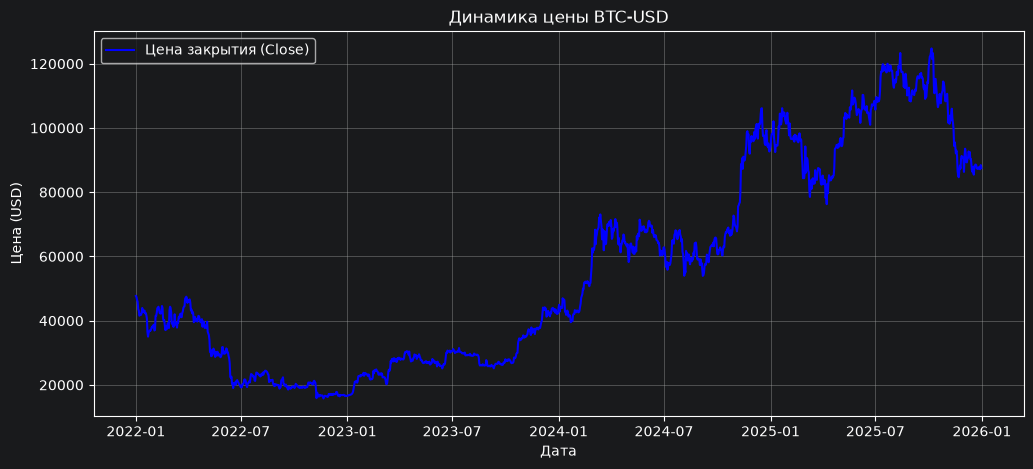

In [10]:
print('Информация о датасете:')
print(df.info())

print('\nОписательная статистика:')
print(df.describe())

print('\nКоличество пропусков:')
print(df.isnull().sum())

plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Close'], label='Цена закрытия (Close)', color='blue')
plt.title(f'Динамика цены {ticker}')
plt.xlabel('Дата')
plt.ylabel('Цена (USD)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
data = df[['Open', 'High', 'Low', 'Close', 'Volume']].copy()

lags = list(range(1, 8))
for lag in lags:
  data[f'Close_lag_{lag}'] = data['Close'].shift(lag)

data['SMA_7'] = data['Close'].rolling(window=7).mean()
data['SMA_14'] = data['Close'].rolling(window=14).mean()
data['Volatility_7'] = data['Close'].rolling(window=7).std()

data['Target'] = data['Close'].shift(-1)

last_known_features = data.drop(columns=['Target']).iloc[[-1]].copy()

data.dropna(inplace=True)

X = data.drop(columns=['Target'])
y = data['Target']

split_idx = int(len(data) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f'Размер обучающей выборки: {X_train.shape}')
print(f'Размер тестовой выборки: {X_test.shape}')


In [ ]:
tscv = TimeSeriesSplit(n_splits=5)

models_params = {
    'LinearRegression': {
        'model': LinearRegression(),
        'params': {'regressor__fit_intercept': [True, False]},
    },
    'Ridge': {
        'model': Ridge(random_state=42),
        'params': {
            'regressor__alpha': [0.01, 0.1, 1.0, 10.0, 100.0],
            'regressor__solver': ['auto', 'svd', 'cholesky'],
        },
    },
    'Lasso': {
        'model': Lasso(random_state=42, max_iter=10000),
        'params': {
            'regressor__alpha': [0.01, 0.1, 1.0, 10.0, 50.0],
            'regressor__selection': ['cyclic', 'random'],
        },
    },
}

results = []
best_models = {}

for name, mp in models_params.items():
  pipeline = Pipeline(
      [('scaler', StandardScaler()), ('regressor', mp['model'])]
  )

  grid = GridSearchCV(
      estimator=pipeline,
      param_grid=mp['params'],
      cv=tscv,
      scoring='neg_root_mean_squared_error',
      n_jobs=-1,
  )

  grid.fit(X_train, y_train)
  best_model = grid.best_estimator_
  best_models[name] = best_model

  y_pred = best_model.predict(X_test)

  rmse = np.sqrt(mean_squared_error(y_test, y_pred))
  mae = mean_absolute_error(y_test, y_pred)
  r2 = r2_score(y_test, y_pred)

  results.append({
      'Модель': name,
      'Лучшие параметры': grid.best_params_,
      'RMSE (USD)': round(rmse, 2),
      'MAE (USD)': round(mae, 2),
      'R2': round(r2, 4),
  })

results_df = pd.DataFrame(results).sort_values(by='RMSE (USD)')
print('--- Сравнение моделей на тестовой выборке ---')
print(results_df.to_string(index=False))

best_model_name = results_df.iloc[0]['Модель']
final_model = best_models[best_model_name]
print(f'\nЛучшая модель: {best_model_name}')


In [ ]:
y_test_pred = final_model.predict(X_test)

plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test.values, label='Реальная цена', color='black')
plt.plot(
    y_test.index,
    y_test_pred,
    label=f'Прогноз ({best_model_name})',
    color='red',
    linestyle='--',
)
plt.title(f'Сравнение реальной и предсказанной цены ({ticker}) на тесте')
plt.xlabel('Дата')
plt.ylabel('Цена (USD)')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
horizon = 7
future_predictions = []

history_closes = list(df['Close'].values)
current_features = last_known_features.copy()

for step in range(1, horizon + 1):
  next_price = float(final_model.predict(current_features)[0])
  future_predictions.append(next_price)

  history_closes.append(next_price)

  next_row = current_features.copy()
  next_row['Open'] = next_price
  next_row['High'] = next_price
  next_row['Low'] = next_price
  next_row['Close'] = next_price

  for lag in lags:
    next_row[f'Close_lag_{lag}'] = history_closes[-1 - lag]

  next_row['SMA_7'] = np.mean(history_closes[-7:])
  next_row['SMA_14'] = np.mean(history_closes[-14:])
  next_row['Volatility_7'] = np.std(history_closes[-7:], ddof=1)

  current_features = next_row

last_date = df.index[-1]
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1), periods=horizon
)

forecast_df = pd.DataFrame(
    {'Дата': future_dates, 'Прогноз цены (USD)': np.round(future_predictions, 2)}
)

print(f'--- Прогноз цены {ticker} на следующие {horizon} дней ---')
print(forecast_df.to_string(index=False))
